# End Semester Exam Notebook: Problem-3

### Name:
### Roll Number:

#### --------------------------------------------------------------------

## 📊 Dataset Description: Mushroom Classification

## 🍄 Mushroom Classification Dataset

This dataset contains descriptions of hypothetical samples corresponding to 23 species of gilled mushrooms in the Agaricus and Lepiota family. Each sample is described by **categorical attributes** related to the mushroom’s physical characteristics such as cap shape, color, odor, gill structure, stalk features, and habitat.

The goal of this task is to **predict whether a mushroom is edible (`e`) or poisonous (`p`)** based on these descriptive features.  

### 🍄 Mushroom Dataset Attribute Information

**Target variable:**  
- `class`: edible = **e**, poisonous = **p**

---

| **Feature** | **Description / Categories** |
|--------------|------------------------------|
| **cap-shape** | bell = **b**, conical = **c**, convex = **x**, flat = **f**, knobbed = **k**, sunken = **s** |
| **cap-surface** | fibrous = **f**, grooves = **g**, scaly = **y**, smooth = **s** |
| **cap-color** | brown = **n**, buff = **b**, cinnamon = **c**, gray = **g**, green = **r**, pink = **p**, purple = **u**, red = **e**, white = **w**, yellow = **y** |
| **bruises** | bruises = **t**, no = **f** |
| **odor** | almond = **a**, anise = **l**, creosote = **c**, fishy = **y**, foul = **f**, musty = **m**, none = **n**, pungent = **p**, spicy = **s** |
| **gill-attachment** | attached = **a**, descending = **d**, free = **f**, notched = **n** |
| **gill-spacing** | close = **c**, crowded = **w**, distant = **d** |
| **gill-size** | broad = **b**, narrow = **n** |
| **gill-color** | black = **k**, brown = **n**, buff = **b**, chocolate = **h**, gray = **g**, green = **r**, orange = **o**, pink = **p**, purple = **u**, red = **e**, white = **w**, yellow = **y** |
| **stalk-shape** | enlarging = **e**, tapering = **t** |
| **stalk-root** | bulbous = **b**, club = **c**, cup = **u**, equal = **e**, rhizomorphs = **z**, rooted = **r**, missing = **?** |
| **stalk-surface-above-ring** | fibrous = **f**, scaly = **y**, silky = **k**, smooth = **s** |
| **stalk-surface-below-ring** | fibrous = **f**, scaly = **y**, silky = **k**, smooth = **s** |
| **stalk-color-above-ring** | brown = **n**, buff = **b**, cinnamon = **c**, gray = **g**, orange = **o**, pink = **p**, red = **e**, white = **w**, yellow = **y** |
| **stalk-color-below-ring** | brown = **n**, buff = **b**, cinnamon = **c**, gray = **g**, orange = **o**, pink = **p**, red = **e**, white = **w**, yellow = **y** |
| **veil-type** | partial = **p**, universal = **u** |
| **veil-color** | brown = **n**, orange = **o**, white = **w**, yellow = **y** |
| **ring-number** | none = **n**, one = **o**, two = **t** |
| **ring-type** | cobwebby = **c**, evanescent = **e**, flaring = **f**, large = **l**, none = **n**, pendant = **p**, sheathing = **s**, zone = **z** |
| **spore-print-color** | black = **k**, brown = **n**, buff = **b**, chocolate = **h**, green = **r**, orange = **o**, purple = **u**, white = **w**, yellow = **y** |
| **population** | abundant = **a**, clustered = **c**, numerous = **n**, scattered = **s**, several = **v**, solitary = **y** |
| **habitat** | grasses = **g**, leaves = **l**, meadows = **m**, paths = **p**, urban = **u**, waste = **w**, woods = **d** |

---

📘 **Note:**  
All features are **categorical**.  
Target variable `class` indicates whether a mushroom is **edible (e)** or **poisonous (p)**.


### Solution - 3 (Start Writing code from below)

In [63]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from pprint import pprint

# ---------------------------
# 1. Load Dataset
# ---------------------------
df = pd.read_csv("data_csv_files/mushrooms_train.csv")
df1 = pd.read_csv("data_csv_files/mushrooms_X_test.csv")
#df.columns = ['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class']

# ---------------------------
# 2. Train-Test Split
# ---------------------------
train_data, test_data = train_test_split(df, test_size=0.2, random_state=42)


In [64]:
# ---------------------------
# 3. Helper Functions for ID3
# ---------------------------

def entropy(target_col):
    """Calculate entropy of a target column"""
    elements, counts = np.unique(target_col, return_counts=True)
    entropy_val = 0
    for i in range(len(elements)):
        prob = counts[i] / np.sum(counts)
        entropy_val += -prob * np.log2(prob)
    return entropy_val

def info_gain(data, split_attribute, target_name="class"):
    """Calculate Information Gain of a feature"""
    total_entropy = entropy(data[target_name])
    vals, counts = np.unique(data[split_attribute], return_counts=True)

    weighted_entropy = np.sum(
        [(counts[i] / np.sum(counts)) * entropy(data[data[split_attribute] == vals[i]][target_name])
         for i in range(len(vals))]
    )
    return total_entropy - weighted_entropy

In [65]:
# ---------------------------
# 4. ID3 Algorithm (Recursive Tree Builder)
# ---------------------------

def id3(data, original_data, features, target_attribute_name="class", parent_class=None, depth=0, max_depth=4):
    """Recursively build ID3 decision tree"""

    # If all target values are same — return that label
    if len(np.unique(data[target_attribute_name])) <= 1:
        return np.unique(data[target_attribute_name])[0]

    # If dataset is empty — return majority class of original dataset
    elif len(data) == 0:
        return np.unique(original_data[target_attribute_name])[
            np.argmax(np.unique(original_data[target_attribute_name], return_counts=True)[1])
        ]

    # If no features left — return majority class of current data
    elif len(features) == 0 or depth == max_depth:
        return np.unique(data[target_attribute_name])[
            np.argmax(np.unique(data[target_attribute_name], return_counts=True)[1])
        ]

    # Otherwise, choose the feature with max information gain
    else:
        parent_class = np.unique(data[target_attribute_name])[
            np.argmax(np.unique(data[target_attribute_name], return_counts=True)[1])
        ]
        gains = [info_gain(data, feature, target_attribute_name) for feature in features]
        best_feature = features[np.argmax(gains)]

        # Initialize the tree with the best feature
        tree = {best_feature: {}}

        # Remove the used feature from list
        features = [f for f in features if f != best_feature]

        # For each possible value of the best feature, build subtree
        for value in np.unique(data[best_feature]):
            sub_data = data[data[best_feature] == value]
            subtree = id3(sub_data, df, features, target_attribute_name, parent_class, depth + 1, max_depth)
            tree[best_feature][value] = subtree

        return tree
        

In [66]:
# training
features = list(df.columns[:-1])
tree = id3(train_data, train_data, features)
print("\nDecision Tree (up to 4 levels):")
pprint(tree, width=120)


Decision Tree (up to 4 levels):
{'odor': {'a': 'e',
          'c': 'p',
          'f': 'p',
          'l': 'e',
          'm': 'p',
          'n': {'spore-print-color': {'b': 'e',
                                      'h': 'e',
                                      'k': 'e',
                                      'n': 'e',
                                      'o': 'e',
                                      'r': 'p',
                                      'w': {'habitat': {'d': {'gill-size': {'b': 'e', 'n': 'p'}},
                                                        'g': 'e',
                                                        'l': {'cap-color': {'c': 'e', 'n': 'e', 'w': 'p', 'y': 'p'}},
                                                        'p': 'e',
                                                        'w': 'e'}},
                                      'y': 'e'}},
          'p': 'p',
          's': 'p',
          'y': 'p'}}


In [67]:
# ---------------------------
# 5. Prediction Function
# ---------------------------

def predict(query, tree, default="unacc"):
    """Predict the class for a single example"""
    for key in list(query.keys()):
        if key in tree.keys():
            try:
                result = tree[key][query[key]]
            except:
                return default
            if isinstance(result, dict):
                return predict(query, result)
            else:
                return result
    return default

def predict_all(test_data, tree):
    """Predict for multiple rows"""
    predictions = []
    for i in range(len(test_data)):
        query = test_data.iloc[i, :-1].to_dict()
        prediction = predict(query, tree)
        predictions.append(prediction)
    return predictions

In [68]:
# ---------------------------
# 6. Evaluate Accuracy
# ---------------------------
predictions = predict_all(test_data, tree)
acc = accuracy_score(test_data["class"], predictions)
print("\nAccuracy on test set:", round(acc * 100, 2), "%")


Accuracy on test set: 100.0 %


In [69]:
# ---------------------------
# 7. Tree Depth Function
# ---------------------------

def tree_depth(tree):
    """Find depth and breadth of the tree"""
    if not isinstance(tree, dict):
        return 0, 1  # (depth, breadth)
    else:
        depths = []
        breadths = []
        for key in tree.keys():
            for value in tree[key].values():
                d, b = tree_depth(value)
                depths.append(1 + d)
                breadths.append(b)
        return max(depths), sum(breadths)


depth, breadth = tree_depth(tree)
print("\nTree Depth:", depth)
print("Tree Breadth:", breadth)


Tree Depth: 4
Tree Breadth: 24


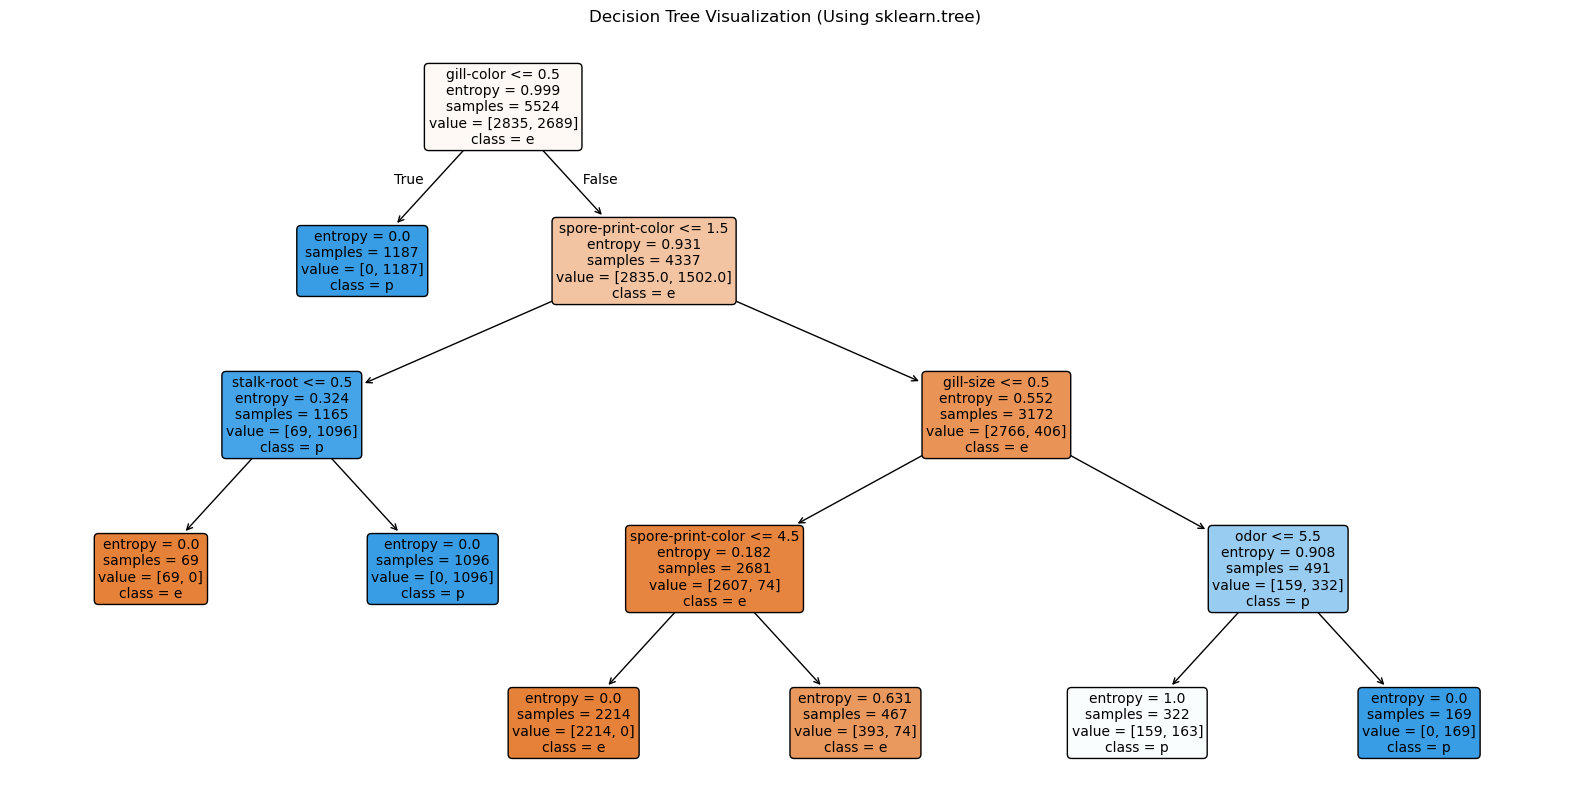

In [70]:
from sklearn import tree
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier

# ---------------------------
# Encode Categorical Variables
# ---------------------------
# sklearn's DecisionTreeClassifier requires numerical input
df_encoded = df.copy()
le_dict = {}
for column in df_encoded.columns:
    le = LabelEncoder()
    df_encoded[column] = le.fit_transform(df_encoded[column])
    le_dict[column] = le  # store encoders for reverse mapping if needed

# ---------------------------
# Train-Test Split
# ---------------------------
X = df_encoded.drop("class", axis=1)
y = df_encoded["class"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ---------------------------
# Train sklearn Decision Tree (ID3-like)
# ---------------------------
clf = DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=42)
clf.fit(X_train, y_train)

# ---------------------------
# Visualization using plot_tree
# ---------------------------
plt.figure(figsize=(20, 10))
tree.plot_tree(
    clf,
    feature_names=X.columns,
    class_names=le_dict["class"].classes_,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Visualization (Using sklearn.tree)")
plt.show()


In [71]:
# ---------------------------
# Retrain-Test Split
# ---------------------------
train_data1, test_data1 = train_test_split(df, train_size=1, random_state=42)

In [72]:
# training
features = list(df.columns[:-1])
tree = id3(train_data1, train_data1, features)
print("\nDecision Tree (up to 4 levels):")
pprint(tree, width=120)


Decision Tree (up to 4 levels):
'e'


In [78]:
predictions = predict_all(test_data1, tree)
acc = accuracy_score(test_data1["class"], predictions)

AttributeError: 'str' object has no attribute 'keys'

In [77]:
b = pd.DataFrame(predictions)
b.to_csv("output_files/predictions_3.csv")